In [50]:
import numpy as np
import sys
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
import os
import csv
np.set_printoptions(threshold=sys.maxsize, precision=2, suppress=True)
import matplotlib as mpl
from scipy.stats import expon

0  - Pronghorn \
1  - Coyote \
2  - Small Mammals \
3  - Elk \
4  - Woody Plants \
5  - Stream Morphology \
6  - Beaver \
7  - Birds \
8  - Berries \
9 - Bear \
10 - Scavengers \
11 - Wolf

Importing the human population changes 

In [3]:
current_directory = os.path.dirname(os.path.abspath('Ensemble-Ecosystem-Model'))
file_name = 'Annual Park Recreation Visitation (1904 - Last Calendar Year).csv'
file_path = os.path.join(current_directory, file_name)

data = []
with open(file_path, mode="r") as file:
    reader = csv.reader(file)
    count = 0
    for row in reader:
        count += 1
        if count > 4 and len(row) > 2:
            year = int(row[0])
            visitor_num = int(row[1].replace(",", ""))
            total_pop = int(row[2].replace(",", ""))
            data.append([year, visitor_num, total_pop])
population_data = np.vstack(np.array(data))

In [4]:
def interaction_matrix(N):
    int_mat = np.zeros((N, N))

    #Pronghorn
    int_mat[0, 1] = 1 #Coyote

    #Coyote
    int_mat[1, 0] = -1 #Pronghorn
    int_mat[1, 2] = -1 #Small Mammals
    int_mat[1, 3] = -1 #Elk

    #Small Mammals
    int_mat[2, 1] = 1 #Coyote

    #Elk
    int_mat[3, 1] = 1 #Coyote
    int_mat[3, 4] = -1 #Woody Plants
    int_mat[3, 9] = 1 #Bear
    int_mat[3, 10] = 1 #Scavengers
    int_mat[3, 11] = 1 #Wolf

    #Woody Plants
    int_mat[4, 3] = 1 #Elk
    int_mat[4, 5] = 1 #Stream Morphology
    int_mat[4, 6] = 1 #Beaver
    int_mat[4, 7] = 1 #Birds
    int_mat[4, 8] = 1 #Berries

    #Berries
    int_mat[8, 9] = 1 #Bear

    #Bear
    int_mat[9, 3] = -1 #Elk
    int_mat[9, 4] = 1 #Woody Plants

    #Wolf
    int_mat[11, 1] = -1 #Coyote
    int_mat[11, 3] = -1 #Elk

    return int_mat

In [ ]:
def A_matrix(int_mat, N):

    #a_i,i < 0
    A = int_mat - np.identity(N)

    #Interaction in uniform distribution
    A = np.multiply(A, np.random.uniform(size=A.shape))

    #Predator-prey special case
    for i in np.arange(N):
        for j in np.arange(N):
            if int_mat[i, j] == -1 and int_mat[j, i] == 1:
                A[i, j] = np.random.uniform(-0.2*A[j, i], 0)
            
    return A

def r_vec_known():
    #r_known[0] = Wolf
    #r_known[1] = Elk
    #r_known[2] = Bear
    r_known = np.array([1.29, 0.18, 0.045])

    for i in np.arange(len(r_known)):
        #Known rate should median not mean?
        r_known[i] = np.random.lognormal(r_known[i], 0.5) 

    return r_known

def r_vec(N):

    #Generate known rates
    r_known = r_vec_known()

    #Sample unkown rates
    r_max = np.max(r_known)
    r = np.random.uniform(0, r_max, size=N)
    
    #Set known rates
    r[3] = r_known[1] #Elk
    r[9] = r_known[2] #Bear
    r[11] = r_known[0] #Wolf

    return r


def jacobian(A, r, n, N):

    #Compute Jacobian as defined in the paper
    J = np.multiply(A, n)
    diag = r + A@n
    J += diag * np.identity(N)

    return J

def check_positive(x):

    #Return true iff all values are positive
    for i in np.arange(len(x)):
        if x[i] <= 0:
            return False
        
    return True

def viable(A, r, n_eq, N):
    
    #Check if equilibrium populations are positive
    if check_positive(n_eq):

        #Equilibria must be stable
        #(Real part of eigenvalues of the Jacobian are negative)
        J_eq = jacobian(A, r, n_eq, N) 
        eig_val, eig_vec = np.linalg.eig(J_eq)
        return check_positive(-eig_val.real)
    
    return False

def introduce_species(n):

    #Initial population of introduced species  = 10% of smallest population
    new_pop = 0.1*np.min(n)
    return np.concatenate((n, [new_pop]))

def generate_viable_models(M):

    #Get matrix of interaction network
    N=12
    int_mat = interaction_matrix(N)

    #Initialize arrays for parameters and equilibrium populations
    As = np.zeros((M, N, N))
    rs = np.zeros((M, N))
    ns = np.zeros((M, N))

    #Generate M viable models
    i = 0 #Index of viable models
    j = 0 #Overall index
    
    while i < M:

        #Generate parameters
        A = A_matrix(int_mat, N)
        r = r_vec(N)

        #Calculate equilibria without wolf
        A_init = A[0:N-1, 0:N-1]
        r_init = r[0:N-1]
        n_eq = -np.linalg.inv(A_init)@r_init

        #Store parameters if viable
        if viable(A_init, r_init,n_eq, N-1):
            As[i] = A
            rs[i] = r
            ns[i] = introduce_species(n_eq) #Introduced species is added here
            i += 1

        j += 1

    return As, rs, ns

#Rate equation
def mod_lot_vol(t, n, A, r):
    return np.multiply(r, n) + np.multiply(A@n, n)


def simulate_eem(As, rs, ns_init, M, N):
    dt = 0.1
    t_max = 30
    t_eval = np.arange(0, t_max, dt)
    ns = np.zeros((M, len(t_eval), N))

    for i in np.arange(M):
        sol = solve_ivp(mod_lot_vol, (0, t_max), ns_init[i], t_eval=t_eval, args=(As[i], rs[i]))
        ns[i] = np.transpose(sol.y)

    return t_eval, ns

In [6]:
M = 100
N = 12
As, rs, ns_init = generate_viable_models(M)
ts, ns = simulate_eem(As, rs, ns_init, M, N)

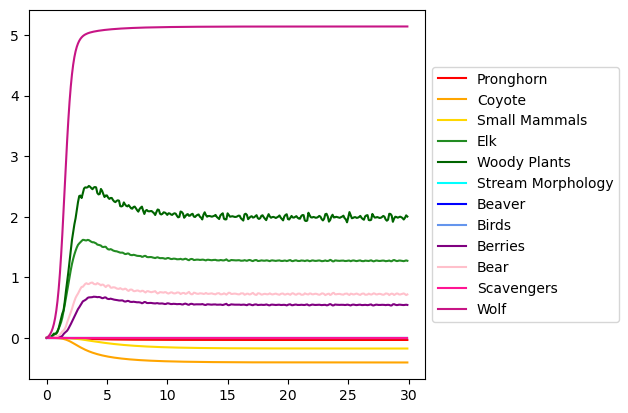

In [44]:
fig = plt.figure()
ax = plt.subplot(111)

# colors_range = mpl.cm.tab20(range(20))
colors_range = [
    "Red", "Orange", "gold", "forestgreen", "darkgreen",
    "Cyan", "Blue", "cornflowerblue", "Purple", "Pink",
    "deeppink", "mediumvioletred"
]

labels = ['Pronghorn', 'Coyote', 'Small Mammals', 'Elk', 'Woody Plants', 'Stream Morphology', 'Beaver', 'Birds', 'Berries', 'Bear', 'Scavengers', 'Wolf']
for i in np.arange(N):
    ax.plot(ts, ns[0, :, i]-ns_init[0, i], label = labels[i], c = colors_range[i])

box = ax.get_position()
ax.set_position([box.x0, box.y0, box.width * 0.8, box.height])

ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))

plt.show()

Fitted coefficients: a = 91.87525716635612, b = -323115.1776591423, c = 281814684.3342347


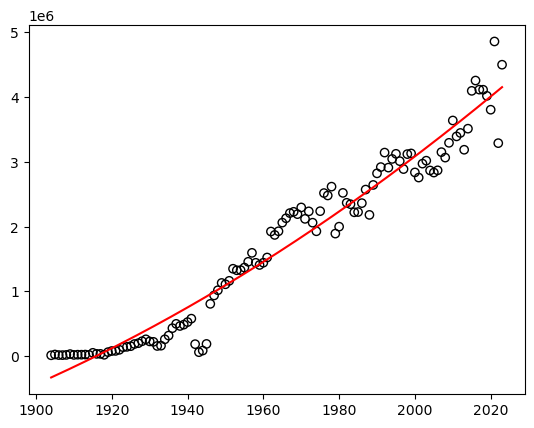

In [53]:
x_data = population_data[:, 0]
y_data = population_data[:, 1]

coefficients = np.polyfit(x_data, y_data, 2)

a, b, c = coefficients
print(f"Fitted coefficients: a = {a}, b = {b}, c = {c}")

x_fit = np.linspace(min(x_data), max(x_data), 500)  # Fine-grained x for smooth curve
y_fit = a * x_fit**2 + b * x_fit + c

plt.plot(x_fit, y_fit, label=f"Fitted Curve: $y = {a:.2e}x^2 + {b:.2e}x + {c:.2e}$", color="red")
# plt.yscale('log')
plt.scatter(x_data, y_data, facecolor = 'none', edgecolors= 'k')
# plt.plot(x, pdf_fitted, 'r-', lw=2, label='Exponential Fit')